# 🏗️ ODS3 / BO3 — CAPEX Scoring & Smart Zone Ranking
## Deep Learning Pipeline pour l'Investissement Réseau Intelligent

> **Objectif Business** : Identifier les zones géographiques prioritaires pour les investissements CAPEX réseau, maximiser le ROI et améliorer la QoS là où c'est le plus nécessaire.

> **Dataset** : Nigerian Telecom Quality of Service Metrics

---

## 📋 Architecture du Pipeline

```
RAW DATA
    │
    ▼
[Étape 1] Data Loading & EDA rapide
    │
    ▼
[Étape 2] Feature Engineering CAPEX
          → CAPEX Score (target composite)
          → Zone Performance Index
          → Network Gap Score
    │
    ▼
[Étape 3] Preprocessing & Normalisation
    │
    ├──────────────────────────────────┐
    ▼                                  ▼
[Étape 4] MLP                    [Étape 5] LSTM/GRU
Dense Neural Network             Temporal Patterns
    │                                  │
    ├──────────────────────────────────┘
    ▼
[Étape 6] TabNet
Attention-based Tabular Transformer
    │
    ▼
[Étape 7] Autoencoder
Anomaly Detection & Zone Compression
    │
    ▼
[Étape 8] CAPEX Zone Ranking
          → Top zones à investir
          → Carte de chaleur priorités
          → Recommandations BO3
```

| Modèle | Tâche | Sortie |
|--------|-------|--------|
| **MLP** | Régression CAPEX Score | Score 0-100 par zone |
| **LSTM/GRU** | Prédiction temporelle | Évolution future QoS |
| **TabNet** | Classification priorité | Urgence investissement |
| **Autoencoder** | Détection zones critiques | Anomalies réseau |


---
## 🔹 Étape 1 — Setup & Data Loading


In [1]:
# Installation
!pip install datasets torch torchvision pytorch-tabnet shap --quiet


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.0.2 which is incompatible.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.0.2 which is incompatible.
spyder 5.5.1 requires ipython!=8.17.1,<9.0.0,>=8.13.0; python_version > "3.8", but you have ipython 9.10.0 which is incompatible.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, Dataset

# TabNet
from pytorch_tabnet.tab_model import TabNetRegressor, TabNetClassifier

# Sklearn
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OrdinalEncoder
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, f1_score, roc_auc_score, classification_report
)
import shap

# Config
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 13, 'axes.titleweight': 'bold'})
print('Librairies chargees !')



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\User\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\User\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\User\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 758, in start
    self.io_loop.

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.0.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



ImportError: numpy.core.multiarray failed to import

Shape : (200000, 13)
Colonnes : ['metric_id', 'timestamp', 'tower_id', 'city', 'operator', 'network_type', 'latency_ms', 'jitter_ms', 'throughput_mbps', 'packet_loss_rate', 'error_rate', 'signal_strength_dbm', 'active_users']


,metric_id,timestamp,tower_id,city,operator,network_type,latency_ms,jitter_ms,throughput_mbps,packet_loss_rate,error_rate,signal_strength_dbm,active_users
0,QOS00000001,2025-09-30 19:54:00,CAL-6586,Calabar,Glo,4G,33.48,12.55,32.41,3.27,1.995,-97,95
1,QOS00000002,2025-09-23 02:05:00,ABA-2144,Aba,Airtel,4G,24.42,26.91,94.59,1.36,1.229,-82,487
2,QOS00000003,2025-09-10 06:02:00,BEN-4261,Benin City,Glo,4G,48.78,16.10,76.02,4.74,0.027,-102,138



  2. ANALYSE STRUCTURELLE DU DATASET (BO3 – CAPEX)  

→ Dimensions du dataset :
Nombre de lignes : 200000
Nombre de colonnes : 40
→ 
Types des variables :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 40 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   metric_id             200000 non-null  object        
 1   timestamp             200000 non-null  datetime64[ns]
 2   tower_id              200000 non-null  object        
 3   city                  200000 non-null  object        
 4   operator              200000 non-null  object        
 5   network_type          200000 non-null  object        
 6   latency_ms            200000 non-null  float64       
 7   jitter_ms             200000 non-null  float64       
 8   throughput_mbps       200000 non-null  float64       
 9   packet_loss_rate      200000 non-null  float64       
 10  error_rate          

,count,mean,std,min,25%,50%,75%,max
latency_ms,200000.0,64.367914,71.636071,5.000000,29.170000,4.067500e+01,69.330000,499.840000
jitter_ms,200000.0,15.470445,8.381414,1.000000,8.200000,1.546000e+01,22.730000,30.000000
throughput_mbps,200000.0,64.487387,128.381339,0.100000,8.250000,3.798000e+01,72.410000,999.970000
packet_loss_rate,200000.0,2.498449,1.444993,0.000000,1.240000,2.505000e+00,3.750000,5.000000
error_rate,200000.0,1.001815,0.576954,0.000000,0.503000,1.003000e+00,1.502000,2.000000
signal_strength_dbm,200000.0,-80.013880,17.569604,-110.000000,-95.000000,-8.000000e+01,-65.000000,-50.000000
active_users,200000.0,254.622765,141.371721,10.000000,133.000000,2.540000e+02,377.000000,500.000000
latency_capped,200000.0,64.016055,69.701682,5.000000,29.170000,4.067500e+01,69.330000,429.070600
throughput_capped,200000.0,63.534981,122.212410,0.100000,8.250000,3.798000e+01,72.410000,812.982300
capex_score,200000.0,51.528405,9.716345,3.554277,45.553447,5.151925e+01,57.554194,97.034868


→ 
Valeurs manquantes par colonne :


'Aucune valeur manquante détectée.'


  3. VÉRIFICATION DES DOUBLONS  

Nombre total de lignes dupliquées : 0
Aucun doublon détecté – données exploitables pour le scoring CAPEX.

  4. ANALYSE DES OUTLIERS (MÉTHODE IQR – BO3)  


→ latency_ms
   Outliers : 20055 (10.03%)
   Intervalle normal (IQR) : [-31.07 ; 129.57]
   ⚠️ Indicateur critique → zone prioritaire pour investissement CAPEX

→ jitter_ms
   Outliers : 0 (0.00%)
   Intervalle normal (IQR) : [-13.60 ; 44.53]

→ throughput_mbps
   Outliers : 9171 (4.59%)
   Intervalle normal (IQR) : [-87.99 ; 168.65]

→ packet_loss_rate
   Outliers : 0 (0.00%)
   Intervalle normal (IQR) : [-2.52 ; 7.51]

→ error_rate
   Outliers : 0 (0.00%)
   Intervalle normal (IQR) : [-1.00 ; 3.00]

→ signal_strength_dbm
   Outliers : 0 (0.00%)
   Intervalle normal (IQR) : [-140.00 ; -20.00]

→ active_users
   Outliers : 0 (0.00%)
   Intervalle normal (IQR) : [-233.00 ; 743.00]

→ latency_capped
   Outliers : 20055 (10.03%)
   Intervalle normal (IQR) : [-31.07 ; 129.57]
   ⚠️ Indicateur critique

,Variable,Nb_Outliers,%_Outliers,Borne_inf_IQR,Borne_sup_IQR
16,zone_avg_latency,26893,13.45,62.90,65.84
20,zone_count,26124,13.06,13162.00,13562.00
11,throughput_per_user,23757,11.88,-0.42,0.80
7,latency_capped,20055,10.03,-31.07,129.57
0,latency_ms,20055,10.03,-31.07,129.57
12,latency_jitter_ratio,20005,10.00,-5.38,13.28
10,network_efficiency,9950,4.98,-2.81,4.91
8,throughput_capped,9171,4.59,-87.99,168.65
2,throughput_mbps,9171,4.59,-87.99,168.65
9,capex_score,5154,2.58,27.55,75.56



  5. VISUALISATION DES OUTLIERS – KPI RÉSEAU  



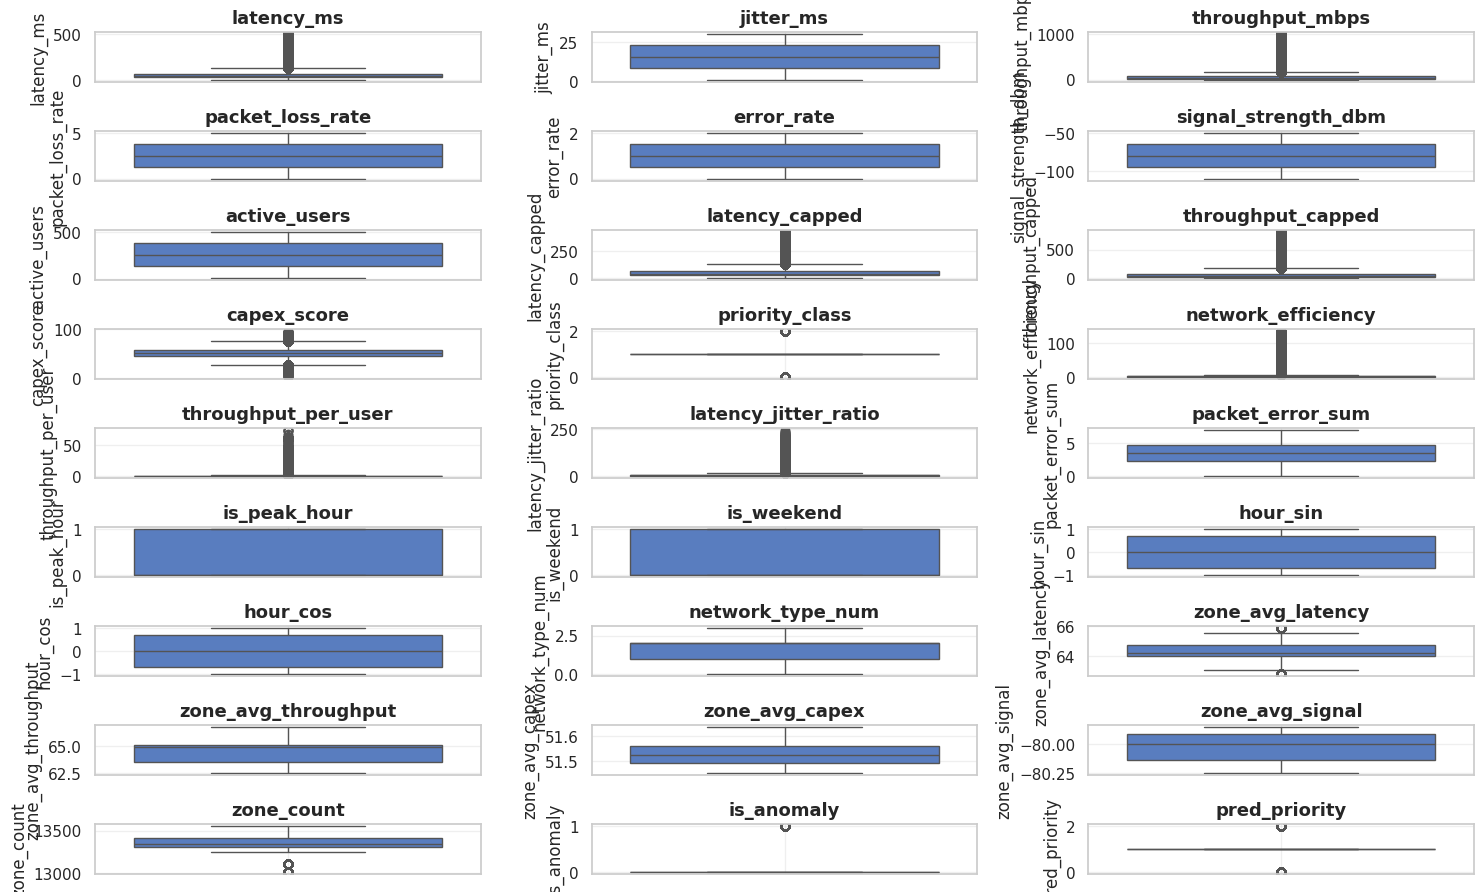


  6. ANALYSE COMPARATIVE PAR TYPE DE RÉSEAU  



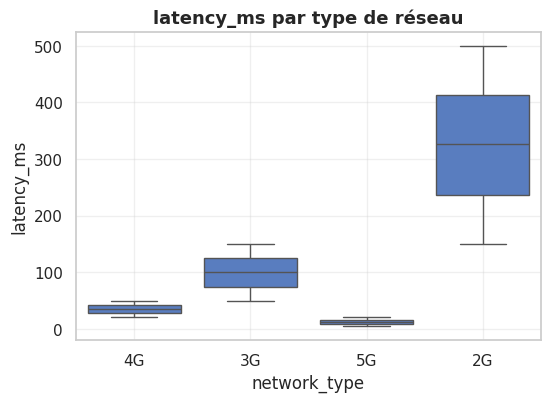

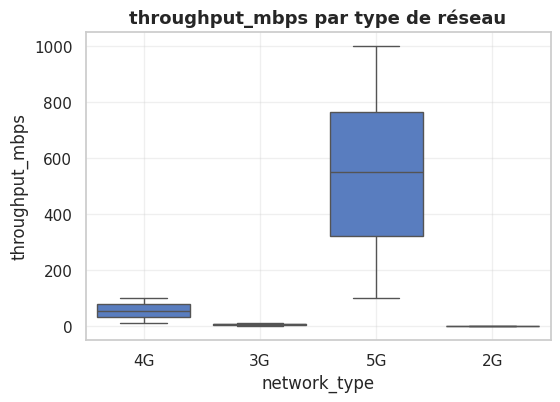

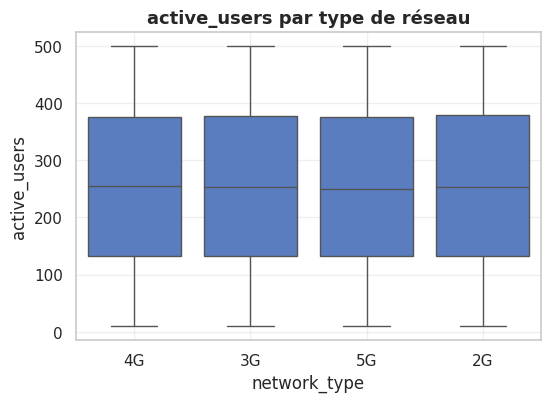


  ANALYSE EXPLORATOIRE TERMINÉE – BO3 CAPEX  

✔ Dataset nettoyé et compris
✔ KPIs critiques identifiés
✔ Base solide pour le modèle de scoring CAPEX


In [ ]:
# Chargement dataset


# ────────────────────────────────────────────────
# Fonctions pour titres colorés et en gras
# ────────────────────────────────────────────────
def print_bold_title(text, color='blue'):
    colors = {
        'blue': '\033[1;34m', 'green': '\033[1;32m', 'yellow': '\033[1;33m',
        'red': '\033[1;31m', 'cyan': '\033[1;36m', 'magenta': '\033[1;35m',
        'white': '\033[1;37m', 'end': '\033[0m'
    }
    print(f"\n{colors[color]}{'=' * 70}{colors['end']}")
    print(f"{colors[color]}  {text.upper()}  {colors['end']}")
    print(f"{colors[color]}{'=' * 70}{colors['end']}\n")


def print_subtitle(text, color='white'):
    colors = {
        'blue': '\033[1;34m', 'green': '\033[1;32m', 'yellow': '\033[1;33m',
        'red': '\033[1;31m', 'cyan': '\033[1;36m', 'magenta': '\033[1;35m',
        'white': '\033[1;37m', 'end': '\033[0m'
    }
    print(f"{colors[color]}→ {text}{colors['end']}")


dataset = load_dataset('electricsheepafrica/nigerian-telecom-quality-of-service-metrics')
df_raw = dataset['train'].to_pandas()

print(f'Shape : {df_raw.shape}')
print(f'Colonnes : {list(df_raw.columns)}')
display(df_raw.head(3))
# ────────────────────────────────────────────────
# 2. Informations générales sur le DataFrame
# ────────────────────────────────────────────────

print_bold_title("2. Analyse Structurelle du Dataset (BO3 – CAPEX)", color='green')

print_subtitle("Dimensions du dataset :", color='cyan')
n_rows, n_cols = df.shape
print(f"Nombre de lignes : {n_rows}")
print(f"Nombre de colonnes : {n_cols}")

print_subtitle("\nTypes des variables :", color='cyan')
df.info()

# Variables numériques utiles pour CAPEX / réseau
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

print_subtitle("\nRésumé statistique (variables numériques – KPI réseau & charge) :", color='cyan')
display(df[numerical_cols].describe().T)

print_subtitle("\nValeurs manquantes par colonne :", color='cyan')
missing = df.isnull().sum()
missing = missing[missing > 0]
display(missing if not missing.empty else "Aucune valeur manquante détectée.")


# ────────────────────────────────────────────────
# 3. Détection des doublons
# ────────────────────────────────────────────────

print_bold_title("3. Vérification des doublons", color='magenta')

duplicates = df.duplicated().sum()
print(f"Nombre total de lignes dupliquées : {duplicates}")

if duplicates > 0:
    print("Exemples de doublons (à analyser avant suppression) :")
    display(df[df.duplicated(keep=False)].head())
else:
    print("Aucun doublon détecté – données exploitables pour le scoring CAPEX.")


# ────────────────────────────────────────────────
# 4. Détection des outliers – Méthode IQR
#    (focus CAPEX : congestion, surcharge, anomalies réseau)
# ────────────────────────────────────────────────

print_bold_title("4. Analyse des Outliers (Méthode IQR – BO3)", color='yellow')

def detect_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = series[(series < lower) | (series > upper)]
    return len(outliers), (len(outliers) / len(series)) * 100, lower, upper

outlier_summary = []

for col in numerical_cols:
    series = df[col].dropna()

    if series.nunique() < 5:
        continue  # évite les fausses alertes sur variables quasi-constantes

    count, percent, low, high = detect_outliers_iqr(series)

    outlier_summary.append({
        "Variable": col,
        "Nb_Outliers": count,
        "%_Outliers": round(percent, 2),
        "Borne_inf_IQR": round(low, 2),
        "Borne_sup_IQR": round(high, 2)
    })

    print(f"\n→ {col}")
    print(f"   Outliers : {count} ({percent:.2f}%)")
    print(f"   Intervalle normal (IQR) : [{low:.2f} ; {high:.2f}]")

    # Lecture CAPEX (texte jury)
    if percent > 5:
        print("   ⚠️ Indicateur critique → zone prioritaire pour investissement CAPEX")

print("\nRésumé global des outliers (vision décisionnelle CAPEX) :")
outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df.sort_values("%_Outliers", ascending=False))


# ────────────────────────────────────────────────
# 5. Visualisation des Outliers (Boxplots globaux)
# ────────────────────────────────────────────────

print_bold_title("5. Visualisation des Outliers – KPI Réseau", color='blue')

plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot((len(numerical_cols) // 3) + 1, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col)
    plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ────────────────────────────────────────────────
# 6. Analyse comparative par Type de Réseau (si disponible)
# ────────────────────────────────────────────────

if 'network_type' in df.columns:
    print_bold_title("6. Analyse Comparative par Type de Réseau", color='red')

    capex_metrics = [c for c in numerical_cols if any(
        k in c.lower() for k in ['latency', 'throughput', 'users', 'traffic', 'load']
    )]

    for metric in capex_metrics[:3]:  # limite pour lisibilité
        plt.figure(figsize=(6, 4))
        sns.boxplot(x='network_type', y=metric, data=df)
        plt.title(f"{metric} par type de réseau")
        plt.grid(alpha=0.3)
        plt.show()


print_bold_title("Analyse Exploratoire Terminée – BO3 CAPEX", color='green')
print("✔ Dataset nettoyé et compris")
print("✔ KPIs critiques identifiés")
print("✔ Base solide pour le modèle de scoring CAPEX")


---
## 🔹 Étape 2 — Feature Engineering CAPEX

> Construction des indicateurs métier pour le scoring d'investissement.

### 📐 Logique de scoring CAPEX

Le **CAPEX Score** mesure l'urgence d'investissement dans une zone :
- **Score élevé** → zone sous-performante avec forte demande → investissement prioritaire
- **Score faible** → zone déjà bien couverte → faible priorité

```
CAPEX_Score = f(
    latence_elevee,         # pénalité forte
    faible_debit,           # pénalité forte
    perte_paquets,          # pénalité modérée
    signal_faible,          # pénalité modérée
    nb_utilisateurs,        # amplificateur (+ users = + urgent)
    type_reseau_ancien       # bonus si 2G/3G encore présent
)
```


In [ ]:
df = df_raw.copy()

# ── Parsing temporel ─────────────────────────────────────────
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek
df['month'] = df['timestamp'].dt.month

# ── Capping des outliers ─────────────────────────────────────
df['latency_capped'] = df['latency_ms'].clip(upper=df['latency_ms'].quantile(0.99))
df['throughput_capped'] = df['throughput_mbps'].clip(upper=df['throughput_mbps'].quantile(0.99))

# ── Normalisation interne (0-1) des composantes ──────────────
def norm01(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-8)

lat_score  = norm01(df['latency_capped'])           # plus c'est haut = pire
thr_score  = 1 - norm01(df['throughput_capped'])    # plus c'est bas = pire
pkt_score  = norm01(df['packet_loss_rate'])
err_score  = norm01(df['error_rate'])
sig_score  = 1 - norm01(df['signal_strength_dbm'] + 130)  # signal faible = pire
usr_score  = norm01(df['active_users'])             # beaucoup d'users = + urgent

# ── CAPEX Score composite (0-100) ────────────────────────────
df['capex_score'] = (
    lat_score  * 0.25 +
    thr_score  * 0.25 +
    pkt_score  * 0.15 +
    err_score  * 0.10 +
    sig_score  * 0.15 +
    usr_score  * 0.10
) * 100

# ── Classe de priorité (target classification) ───────────────
df['priority_class'] = pd.cut(
    df['capex_score'],
    bins=[0, 33, 66, 100],
    labels=[0, 1, 2],   # 0=Low, 1=Medium, 2=High
    include_lowest=True
).astype(int)

# ── Features additionnelles ──────────────────────────────────
df['network_efficiency'] = df['throughput_capped'] / (df['latency_capped'] + 1)
df['throughput_per_user'] = df['throughput_capped'] / (df['active_users'] + 1)
df['latency_jitter_ratio'] = df['latency_ms'] / (df['jitter_ms'] + 1)
df['packet_error_sum'] = df['packet_loss_rate'] + df['error_rate']
df['is_peak_hour'] = df['hour'].isin(list(range(7, 10)) + list(range(17, 21))).astype(int)
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

# ── Encodage network_type ─────────────────────────────────────
enc = OrdinalEncoder(categories=[['2G', '3G', '4G', '5G']])
df['network_type_num'] = enc.fit_transform(df[['network_type']]).astype(int)

# ── Zone-level aggregates (par ville) ────────────────────────
zone_stats = df.groupby('city').agg(
    zone_avg_latency=('latency_ms', 'mean'),
    zone_avg_throughput=('throughput_mbps', 'mean'),
    zone_avg_capex=('capex_score', 'mean'),
    zone_avg_signal=('signal_strength_dbm', 'mean'),
    zone_count=('latency_ms', 'count')
).reset_index()
df = df.merge(zone_stats, on='city', how='left')

print(f'Shape apres FE : {df.shape}')
print(f'\nDistribution CAPEX Score :')
print(df['capex_score'].describe().round(2))
print(f'\nDistribution priorite :')
print(df['priority_class'].value_counts().sort_index())


Shape apres FE : (200000, 34)

Distribution CAPEX Score :
count    200000.00
mean         51.53
std           9.72
min           3.55
25%          45.55
50%          51.52
75%          57.55
max          97.03
Name: capex_score, dtype: float64

Distribution priorite :
priority_class
0      5740
1    182212
2     12048
Name: count, dtype: int64


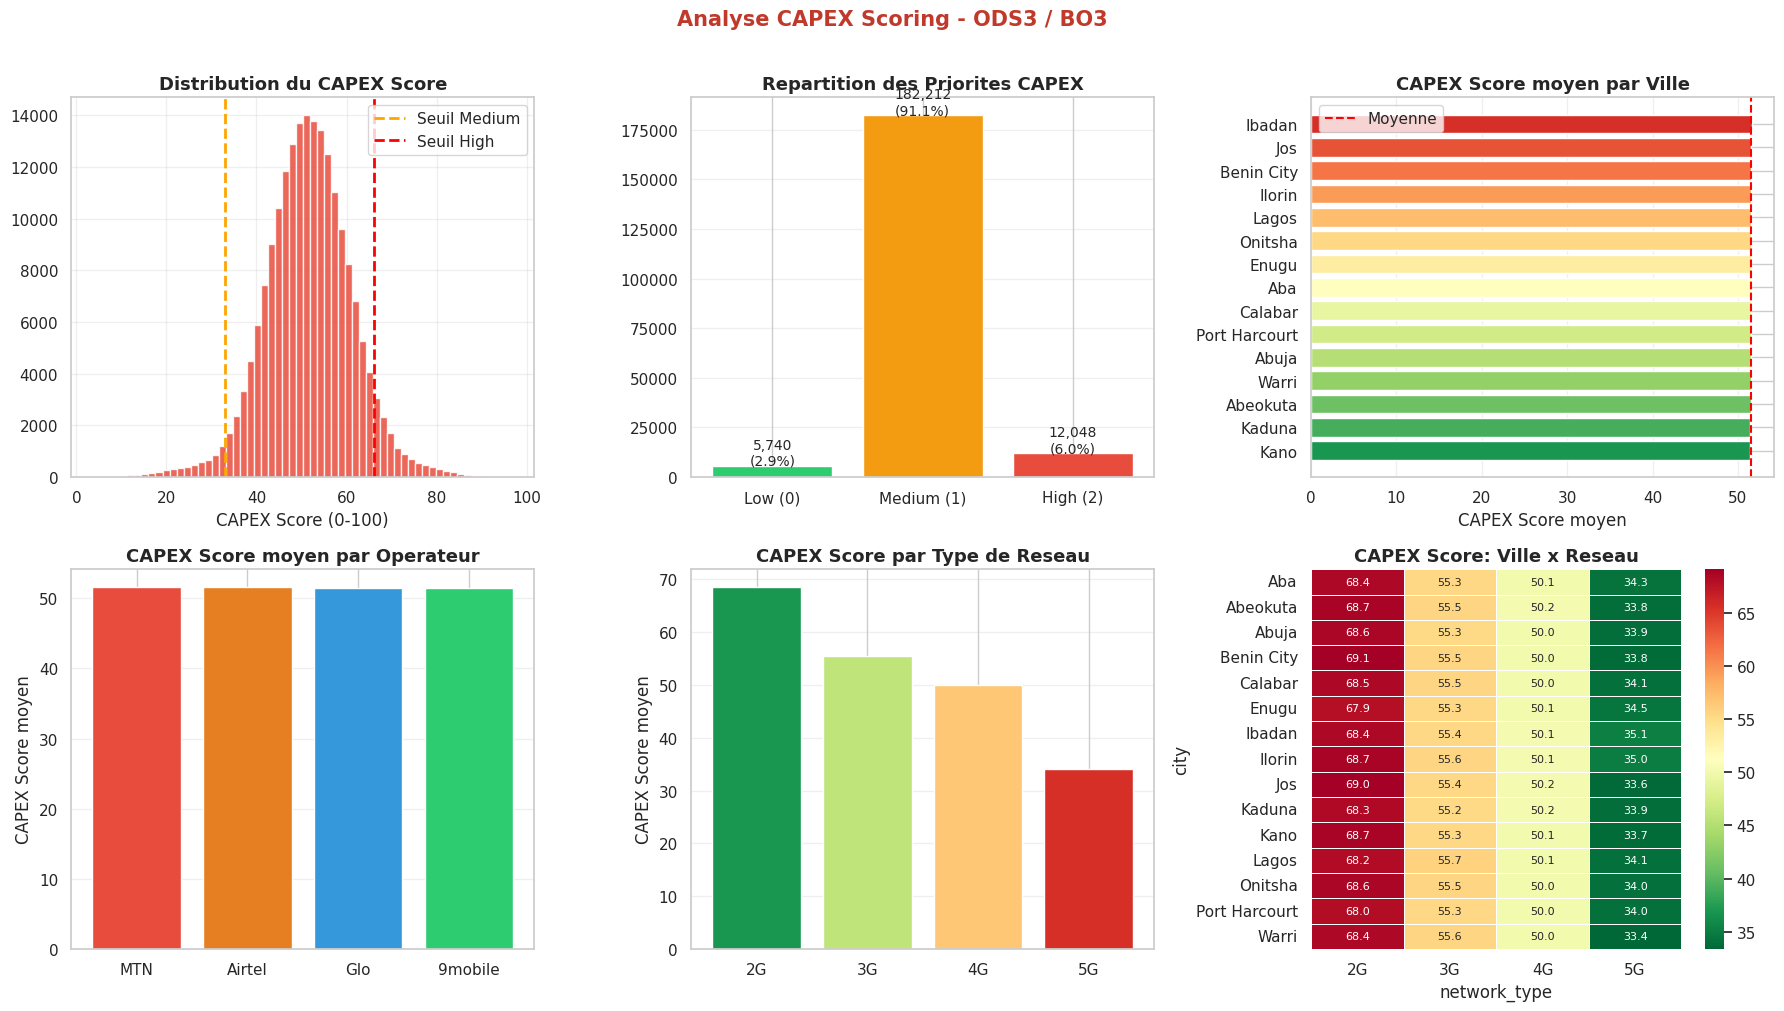

In [ ]:
# Visualisation du CAPEX Score
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Distribution CAPEX Score
axes[0, 0].hist(df['capex_score'], bins=60, color='#e74c3c', edgecolor='white', alpha=0.85)
axes[0, 0].axvline(33, color='orange', lw=2, linestyle='--', label='Seuil Medium')
axes[0, 0].axvline(66, color='red', lw=2, linestyle='--', label='Seuil High')
axes[0, 0].set_title('Distribution du CAPEX Score')
axes[0, 0].set_xlabel('CAPEX Score (0-100)')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Classes de priorité
counts = df['priority_class'].value_counts().sort_index()
bars = axes[0, 1].bar(['Low (0)', 'Medium (1)', 'High (2)'], counts.values,
            color=['#2ecc71', '#f39c12', '#e74c3c'], edgecolor='white')
for bar, v in zip(bars, counts.values):
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, v + 500,
                   f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', fontsize=10)
axes[0, 1].set_title('Repartition des Priorites CAPEX')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# 3. CAPEX moyen par ville
city_capex = df.groupby('city')['capex_score'].mean().sort_values(ascending=True)
colors_city = plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(city_capex)))
bars2 = axes[0, 2].barh(city_capex.index, city_capex.values, color=colors_city)
axes[0, 2].set_title('CAPEX Score moyen par Ville')
axes[0, 2].set_xlabel('CAPEX Score moyen')
axes[0, 2].axvline(city_capex.mean(), color='red', linestyle='--', lw=1.5, label='Moyenne')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3, axis='x')

# 4. CAPEX par opérateur
op_capex = df.groupby('operator')['capex_score'].mean().sort_values(ascending=False)
axes[1, 0].bar(op_capex.index, op_capex.values,
               color=['#e74c3c', '#e67e22', '#3498db', '#2ecc71'][:len(op_capex)],
               edgecolor='white')
axes[1, 0].set_title('CAPEX Score moyen par Operateur')
axes[1, 0].set_ylabel('CAPEX Score moyen')
axes[1, 0].grid(True, alpha=0.3, axis='y')

# 5. CAPEX par type de réseau
net_capex = df.groupby('network_type')['capex_score'].mean().reindex(['2G', '3G', '4G', '5G'])
bars3 = axes[1, 1].bar(net_capex.index, net_capex.values,
                        color=plt.cm.RdYlGn_r([0.1, 0.35, 0.65, 0.9]))
axes[1, 1].set_title('CAPEX Score par Type de Reseau')
axes[1, 1].set_ylabel('CAPEX Score moyen')
axes[1, 1].grid(True, alpha=0.3, axis='y')

# 6. Heatmap CAPEX ville x réseau
pivot = df.pivot_table(values='capex_score', index='city', columns='network_type', aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='RdYlGn_r',
            linewidths=0.5, ax=axes[1, 2], annot_kws={'size': 8})
axes[1, 2].set_title('CAPEX Score: Ville x Reseau')

plt.suptitle('Analyse CAPEX Scoring - ODS3 / BO3', fontsize=15, fontweight='bold',
             color='#c0392b', y=1.01)
plt.tight_layout()
plt.show()


---
## 🔹 Étape 3 — Preprocessing


In [ ]:
# One-Hot Encoding
df_model = df.copy()
df_model = pd.get_dummies(df_model, columns=['city', 'operator'], dtype=int)
df_model = df_model.drop(columns=['network_type', 'timestamp',
                                   'latency_capped', 'throughput_capped'], errors='ignore')

# Features
DROP_COLS = ['capex_score', 'priority_class', 'metric_id', 'tower_id']
FEATURES = [c for c in df_model.columns if c not in DROP_COLS]

X = df_model[FEATURES].values.astype(np.float32)
y_reg = df_model['capex_score'].values.astype(np.float32)        # regression
y_clf = df_model['priority_class'].values.astype(np.int64)       # classification 3 classes

print(f'Features : {len(FEATURES)}')
print(f'Samples  : {len(X):,}')

# Split 70/15/15
X_tmp, X_test, yr_tmp, yr_test, yc_tmp, yc_test = train_test_split(
    X, y_reg, y_clf, test_size=0.15, random_state=SEED, stratify=y_clf)
X_train, X_val, yr_train, yr_val, yc_train, yc_val = train_test_split(
    X_tmp, yr_tmp, yc_tmp, test_size=0.15/0.85, random_state=SEED, stratify=yc_tmp)

print(f'Train : {X_train.shape[0]:,} | Val : {X_val.shape[0]:,} | Test : {X_test.shape[0]:,}')

# Scaling
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train).astype(np.float32)
X_val_sc   = scaler.transform(X_val).astype(np.float32)
X_test_sc  = scaler.transform(X_test).astype(np.float32)

# Target scaler pour regression
yr_scaler = MinMaxScaler()
yr_train_sc = yr_scaler.fit_transform(yr_train.reshape(-1, 1)).ravel().astype(np.float32)
yr_val_sc   = yr_scaler.transform(yr_val.reshape(-1, 1)).ravel().astype(np.float32)

print('Preprocessing OK')


Features : 43
Samples  : 200,000
Train : 139,999 | Val : 30,001 | Test : 30,000
Preprocessing OK


In [ ]:
# Tenseurs PyTorch
def to_tensor(*arrays):
    return [torch.tensor(a) for a in arrays]

Xtr, Xv, Xte = to_tensor(X_train_sc, X_val_sc, X_test_sc)
ytr_r, yv_r   = to_tensor(yr_train_sc, yr_val_sc)
ytr_c, yv_c, yte_c = to_tensor(yc_train, yc_val, yc_test)

# DataLoaders
BATCH = 512

train_ds_reg = TensorDataset(Xtr, ytr_r)
val_ds_reg   = TensorDataset(Xv,  yv_r)
train_dl_reg = DataLoader(train_ds_reg, batch_size=BATCH, shuffle=True)
val_dl_reg   = DataLoader(val_ds_reg,   batch_size=BATCH)

train_ds_clf = TensorDataset(Xtr, ytr_c)
val_ds_clf   = TensorDataset(Xv,  yv_c)
train_dl_clf = DataLoader(train_ds_clf, batch_size=BATCH, shuffle=True)
val_dl_clf   = DataLoader(val_ds_clf,   batch_size=BATCH)

print('DataLoaders prets')


DataLoaders prets


In [ ]:
# Fonctions d'entrainement generiques
def train_epoch_reg(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        pred = model(xb).squeeze()
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
    return total_loss / len(loader.dataset)

def eval_epoch_reg(model, loader, criterion):
    model.eval()
    total_loss = 0
    preds, targets = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb).squeeze()
            total_loss += criterion(pred, yb).item() * len(xb)
            preds.extend(pred.cpu().numpy())
            targets.extend(yb.cpu().numpy())
    return total_loss / len(loader.dataset), np.array(preds), np.array(targets)

def train_epoch_clf(model, loader, optimizer, criterion):
    model.train()
    total_loss, correct = 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
        correct += (pred.argmax(1) == yb).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

def eval_epoch_clf(model, loader, criterion):
    model.eval()
    total_loss, correct = 0, 0
    preds, probas, targets = [], [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out = model(xb)
            loss = criterion(out, yb)
            total_loss += loss.item() * len(xb)
            p = out.argmax(1)
            correct += (p == yb).sum().item()
            preds.extend(p.cpu().numpy())
            probas.extend(torch.softmax(out, dim=1).cpu().numpy())
            targets.extend(yb.cpu().numpy())
    return (total_loss / len(loader.dataset),
            correct / len(loader.dataset),
            np.array(preds), np.array(probas), np.array(targets))

def plot_history(train_losses, val_losses, title, ylabel='Loss'):
    plt.figure(figsize=(10, 4))
    plt.plot(train_losses, label='Train', color='steelblue', lw=2)
    plt.plot(val_losses, label='Validation', color='coral', lw=2)
    best_ep = np.argmin(val_losses)
    plt.axvline(best_ep, color='green', linestyle='--', lw=1.5,
                label=f'Best epoch ({best_ep+1})')
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

print('Fonctions helper definies')


Fonctions helper definies


---
## 🔹 Étape 4 — MLP (Multi-Layer Perceptron)

> Réseau dense profond avec BatchNorm, Dropout et Skip Connections pour prédire le CAPEX Score.

**Architecture :**
```
Input (n_features)
    │
    ├─ Linear(512) → BatchNorm → ReLU → Dropout(0.3)
    ├─ Linear(256) → BatchNorm → ReLU → Dropout(0.3)  ← + Skip Connection
    ├─ Linear(128) → BatchNorm → ReLU → Dropout(0.2)
    ├─ Linear(64)  → BatchNorm → ReLU
    └─ Linear(1)   → Sigmoid × 100  [Régression CAPEX 0-100]
```


In [ ]:
class MLPCapex(nn.Module):
    def __init__(self, input_dim, task='regression', n_classes=3):
        super().__init__()
        self.task = task

        self.block1 = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.block2 = nn.Sequential(
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )
        self.block3 = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2)
        )
        self.block4 = nn.Sequential(
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU()
        )
        # Skip connection : adapter la dimension 512 -> 256
        self.skip1 = nn.Linear(512, 256)

        if task == 'regression':
            self.head = nn.Sequential(nn.Linear(64, 1), nn.Sigmoid())
        else:
            self.head = nn.Linear(64, n_classes)

    def forward(self, x):
        x1 = self.block1(x)
        x2 = self.block2(x1) + self.skip1(x1)  # Skip Connection
        x3 = self.block3(x2)
        x4 = self.block4(x3)
        return self.head(x4)

INPUT_DIM = X_train_sc.shape[1]
print(f'Architecture MLP initialisee - Input dim: {INPUT_DIM}')
model_mlp = MLPCapex(INPUT_DIM, task='regression').to(DEVICE)
print(model_mlp)
total_params = sum(p.numel() for p in model_mlp.parameters())
print(f'\nParametres totaux : {total_params:,}')


Architecture MLP initialisee - Input dim: 43
MLPCapex(
  (block1): Sequential(
    (0): Linear(in_features=43, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
  )
  (block2): Sequential(
    (0): Linear(in_features=512, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
  )
  (block3): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
  )
  (block4): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (skip1): Linear(in_features=512, out_features

In [ ]:
# Entrainement MLP Regression
EPOCHS = 80
LR = 1e-3

model_mlp_reg = MLPCapex(INPUT_DIM, task='regression').to(DEVICE)
optimizer_mlp = optim.AdamW(model_mlp_reg.parameters(), lr=LR, weight_decay=1e-4)
scheduler_mlp = optim.lr_scheduler.CosineAnnealingLR(optimizer_mlp, T_max=EPOCHS)
criterion_reg = nn.MSELoss()

train_losses_mlp, val_losses_mlp = [], []
best_val_loss = float('inf')
best_mlp_state = None

for epoch in range(EPOCHS):
    tr_loss = train_epoch_reg(model_mlp_reg, train_dl_reg, optimizer_mlp, criterion_reg)
    vl_loss, _, _ = eval_epoch_reg(model_mlp_reg, val_dl_reg, criterion_reg)
    scheduler_mlp.step()
    train_losses_mlp.append(tr_loss)
    val_losses_mlp.append(vl_loss)
    if vl_loss < best_val_loss:
        best_val_loss = vl_loss
        best_mlp_state = {k: v.clone() for k, v in model_mlp_reg.state_dict().items()}
    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch+1:3d}/{EPOCHS} | Train={tr_loss:.5f} | Val={vl_loss:.5f}')

model_mlp_reg.load_state_dict(best_mlp_state)
print('\nEntrainement MLP termine !')
plot_history(train_losses_mlp, val_losses_mlp, 'MLP Regression - Courbe apprentissage (MSE Loss)')


In [ ]:
# Evaluation MLP Regression
model_mlp_reg.eval()
with torch.no_grad():
    y_pred_mlp = model_mlp_reg(torch.tensor(X_test_sc).to(DEVICE)).squeeze().cpu().numpy()

# Denormalisation
y_pred_mlp_orig = yr_scaler.inverse_transform(y_pred_mlp.reshape(-1, 1)).ravel()

rmse_mlp = np.sqrt(mean_squared_error(yr_test, y_pred_mlp_orig))
mae_mlp  = mean_absolute_error(yr_test, y_pred_mlp_orig)
r2_mlp   = r2_score(yr_test, y_pred_mlp_orig)

print(f'MLP Regression (Test) :')
print(f'  RMSE : {rmse_mlp:.4f}')
print(f'  MAE  : {mae_mlp:.4f}')
print(f'  R2   : {r2_mlp:.4f}')

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(yr_test[:5000], y_pred_mlp_orig[:5000], alpha=0.3, s=4, color='steelblue')
axes[0].plot([0, 100], [0, 100], 'r--', lw=2)
axes[0].set_xlabel('CAPEX Score Reel')
axes[0].set_ylabel('CAPEX Score Predit')
axes[0].set_title(f'MLP - Reel vs Predit (R2={r2_mlp:.4f})')
axes[0].grid(True, alpha=0.3)

residuals_mlp = yr_test - y_pred_mlp_orig
axes[1].hist(residuals_mlp, bins=60, color='coral', edgecolor='white', alpha=0.85)
axes[1].axvline(0, color='red', lw=2, linestyle='--')
axes[1].set_xlabel('Residuels')
axes[1].set_title(f'MLP - Distribution des Residuels')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
# MLP Classification (3 classes de priorite)
print('MLP Classification - Priorite CAPEX (Low / Medium / High)')

model_mlp_clf = MLPCapex(INPUT_DIM, task='classification', n_classes=3).to(DEVICE)
optimizer_mlp_clf = optim.AdamW(model_mlp_clf.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_clf = optim.lr_scheduler.CosineAnnealingLR(optimizer_mlp_clf, T_max=EPOCHS)
criterion_clf = nn.CrossEntropyLoss()

train_losses_clf, val_losses_clf = [], []
train_accs, val_accs = [], []
best_val_acc = 0
best_mlp_clf_state = None

for epoch in range(EPOCHS):
    tr_loss, tr_acc = train_epoch_clf(model_mlp_clf, train_dl_clf, optimizer_mlp_clf, criterion_clf)
    vl_loss, vl_acc, _, _, _ = eval_epoch_clf(model_mlp_clf, val_dl_clf, criterion_clf)
    scheduler_clf.step()
    train_losses_clf.append(tr_loss)
    val_losses_clf.append(vl_loss)
    train_accs.append(tr_acc)
    val_accs.append(vl_acc)
    if vl_acc > best_val_acc:
        best_val_acc = vl_acc
        best_mlp_clf_state = {k: v.clone() for k, v in model_mlp_clf.state_dict().items()}
    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch+1:3d}/{EPOCHS} | Loss={vl_loss:.4f} | Val Acc={vl_acc:.4f}')

model_mlp_clf.load_state_dict(best_mlp_clf_state)
plot_history(train_accs, val_accs, 'MLP Classification - Accuracy', ylabel='Accuracy')

# Evaluation finale
_, _, y_pred_clf, y_proba_clf, _ = eval_epoch_clf(
    model_mlp_clf,
    DataLoader(TensorDataset(torch.tensor(X_test_sc), yte_c), batch_size=512),
    criterion_clf
)
print('\nRapport de classification :')
print(classification_report(yc_test, y_pred_clf, target_names=['Low', 'Medium', 'High']))


---
## 🔹 Étape 5 — LSTM / GRU (Temporal Patterns)

> Capturer les patterns temporels pour prédire l'évolution future de la QoS et du besoin CAPEX.

**Idée** : On regroupe les mesures par heure pour créer des séquences temporelles par ville/opérateur, puis on entraîne un LSTM et un GRU en parallèle.

**Architecture :**
```
Séquences (batch, seq_len=24, n_features)
    │
    ├─ LSTM(hidden=128, layers=2, bidirectionnel)
    │      └─ Dernier hidden state
    ├─ Dropout(0.3)
    ├─ Linear(64) → ReLU
    └─ Linear(1)  → CAPEX Score
```


In [ ]:
# Construction des sequences temporelles
# On groupe par (city, operator, date) et on cree des sequences de 24h

SEQ_LEN = 24  # 24 heures

# Features pour la sequence
SEQ_FEATURES = ['latency_ms', 'jitter_ms', 'throughput_mbps',
                'packet_loss_rate', 'error_rate', 'signal_strength_dbm',
                'active_users', 'network_efficiency', 'throughput_per_user',
                'packet_error_sum', 'is_peak_hour', 'network_type_num']

df_seq = df.copy()
df_seq['date'] = df_seq['timestamp'].dt.date

# Pour chaque groupe (city, operator, date), on prend les 24 premieres mesures
sequences = []
targets_seq = []

for (city, op, date), grp in df_seq.groupby(['city', 'operator', 'date']):
    grp_sorted = grp.sort_values('hour')
    if len(grp_sorted) >= SEQ_LEN:
        # Prendre une fenetre de SEQ_LEN
        for start in range(0, len(grp_sorted) - SEQ_LEN + 1, SEQ_LEN):
            window = grp_sorted.iloc[start:start + SEQ_LEN]
            # Verifier que les features existent
            available = [f for f in SEQ_FEATURES if f in window.columns]
            seq = window[available].values.astype(np.float32)
            target = window['capex_score'].mean()
            if not np.isnan(seq).any() and not np.isnan(target):
                sequences.append(seq)
                targets_seq.append(target)

X_seq = np.array(sequences)   # (N, SEQ_LEN, n_features)
y_seq = np.array(targets_seq, dtype=np.float32)

print(f'Sequences creees : {X_seq.shape}')
print(f'Targets          : {y_seq.shape}')
print(f'CAPEX moyen      : {y_seq.mean():.2f}')


In [ ]:
# Scaling des sequences
n_samples, seq_len, n_feats = X_seq.shape
X_seq_flat = X_seq.reshape(-1, n_feats)
seq_scaler = StandardScaler()
X_seq_flat_sc = seq_scaler.fit_transform(X_seq_flat).astype(np.float32)
X_seq_sc = X_seq_flat_sc.reshape(n_samples, seq_len, n_feats)

y_seq_sc = ((y_seq - y_seq.min()) / (y_seq.max() - y_seq.min() + 1e-8)).astype(np.float32)
y_seq_raw_range = (y_seq.min(), y_seq.max())

# Split
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(X_seq_sc, y_seq_sc, test_size=0.2, random_state=SEED)
Xs_tr, Xs_val, ys_tr, ys_val = train_test_split(Xs_tr, ys_tr, test_size=0.15, random_state=SEED)

# Tenseurs
BATCH_SEQ = 256
tr_seq_dl  = DataLoader(TensorDataset(torch.tensor(Xs_tr),  torch.tensor(ys_tr)),  batch_size=BATCH_SEQ, shuffle=True)
val_seq_dl = DataLoader(TensorDataset(torch.tensor(Xs_val), torch.tensor(ys_val)), batch_size=BATCH_SEQ)
te_seq_dl  = DataLoader(TensorDataset(torch.tensor(Xs_te),  torch.tensor(ys_te)),  batch_size=BATCH_SEQ)

SEQ_INPUT_DIM = n_feats
print(f'Train seq : {Xs_tr.shape} | Val : {Xs_val.shape} | Test : {Xs_te.shape}')


In [ ]:
class LSTMCapex(nn.Module):
    def __init__(self, input_dim, hidden=128, n_layers=2, dropout=0.3, rnn_type='LSTM'):
        super().__init__()
        self.rnn_type = rnn_type
        rnn_cls = nn.LSTM if rnn_type == 'LSTM' else nn.GRU
        self.rnn = rnn_cls(
            input_size=input_dim,
            hidden_size=hidden,
            num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0,
            bidirectional=True
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Sequential(
            nn.Linear(hidden * 2, 64),   # *2 pour bidirectionnel
            nn.ReLU(),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.dropout(out[:, -1, :])  # dernier timestep
        return self.fc(out)

print('Architecture LSTM/GRU definie')


In [ ]:
# Entrainement LSTM et GRU en parallele
EPOCHS_SEQ = 60
results_rnn = {}

for rnn_name in ['LSTM', 'GRU']:
    print(f'\n--- Entrainement {rnn_name} ---')
    model_rnn = LSTMCapex(SEQ_INPUT_DIM, hidden=128, n_layers=2,
                           dropout=0.3, rnn_type=rnn_name).to(DEVICE)
    opt_rnn = optim.AdamW(model_rnn.parameters(), lr=5e-4, weight_decay=1e-4)
    sch_rnn = optim.lr_scheduler.ReduceLROnPlateau(opt_rnn, patience=5, factor=0.5)
    crit = nn.MSELoss()

    tr_hist, vl_hist = [], []
    best_vl = float('inf')
    best_state = None

    for epoch in range(EPOCHS_SEQ):
        tr_loss = train_epoch_reg(model_rnn, tr_seq_dl, opt_rnn, crit)
        vl_loss, _, _ = eval_epoch_reg(model_rnn, val_seq_dl, crit)
        sch_rnn.step(vl_loss)
        tr_hist.append(tr_loss)
        vl_hist.append(vl_loss)
        if vl_loss < best_vl:
            best_vl = vl_loss
            best_state = {k: v.clone() for k, v in model_rnn.state_dict().items()}
        if (epoch + 1) % 15 == 0:
            print(f'  Epoch {epoch+1}/{EPOCHS_SEQ} | Val Loss={vl_loss:.5f}')

    model_rnn.load_state_dict(best_state)
    plot_history(tr_hist, vl_hist, f'{rnn_name} - Courbe apprentissage')

    # Evaluation test
    _, y_pred_rnn_sc, y_true_rnn = eval_epoch_reg(model_rnn, te_seq_dl, crit)
    # Denorm
    ymin, ymax = y_seq_raw_range
    y_pred_rnn = y_pred_rnn_sc * (ymax - ymin) + ymin
    y_true_rnn_orig = y_true_rnn * (ymax - ymin) + ymin
    rmse = np.sqrt(mean_squared_error(y_true_rnn_orig, y_pred_rnn))
    r2   = r2_score(y_true_rnn_orig, y_pred_rnn)
    results_rnn[rnn_name] = {'model': model_rnn, 'RMSE': rmse, 'R2': r2}
    print(f'  {rnn_name} Test -> RMSE={rmse:.4f} | R2={r2:.4f}')

print('\nComparaison LSTM vs GRU :')
for name, res in results_rnn.items():
    print(f'  {name}: RMSE={res["RMSE"]:.4f} | R2={res["R2"]:.4f}')


---
## 🔹 Étape 6 — TabNet (Attention-based Tabular Transformer)

> TabNet utilise un mécanisme d'attention séquentielle pour sélectionner les features les plus pertinentes à chaque étape de décision — particulièrement adapté aux données tabulaires.

**Points forts de TabNet :**
- Interprétabilité native (attention weights par feature)
- Pas besoin de feature engineering intensif
- Performant sur données tabulaires mixtes
- Sélection de features adaptative à chaque instance

```
Input Features
    │
    ▼
[Step 1] Attention Mask → Features sélectionnées → FC → BN → GLU
    │
[Step 2] Attention Mask → Features sélectionnées → FC → BN → GLU
    │     (basé sur le résidu de l'étape précédente)
   ...
[Step N] Agrégation → Output
```


In [ ]:
# TabNet Regression - CAPEX Score
print('TabNet Regressor - CAPEX Score')

tabnet_reg = TabNetRegressor(
    n_d=32,                  # Dimension embedding par step
    n_a=32,                  # Dimension attention
    n_steps=5,               # Nombre d'etapes de decision
    gamma=1.5,               # Coefficient de sparsite attention
    n_independent=2,
    n_shared=2,
    momentum=0.02,
    lambda_sparse=1e-4,      # Regularisation sparsity
    optimizer_fn=optim.AdamW,
    optimizer_params={'lr': 2e-3, 'weight_decay': 1e-5},
    scheduler_fn=optim.lr_scheduler.CosineAnnealingLR,
    scheduler_params={'T_max': 50},
    mask_type='entmax',      # entmax = attention plus sparse que sparsemax
    seed=SEED,
    verbose=10
)

tabnet_reg.fit(
    X_train_sc, yr_train.reshape(-1, 1),
    eval_set=[(X_val_sc, yr_val.reshape(-1, 1))],
    eval_name=['val'],
    eval_metric=['rmse'],
    max_epochs=100,
    patience=15,
    batch_size=1024,
    virtual_batch_size=256,
    drop_last=False
)

# Evaluation
y_pred_tabnet_reg = tabnet_reg.predict(X_test_sc).ravel()
rmse_tabnet = np.sqrt(mean_squared_error(yr_test, y_pred_tabnet_reg))
mae_tabnet  = mean_absolute_error(yr_test, y_pred_tabnet_reg)
r2_tabnet   = r2_score(yr_test, y_pred_tabnet_reg)

print(f'\nTabNet Regression (Test) :')
print(f'  RMSE : {rmse_tabnet:.4f}')
print(f'  MAE  : {mae_tabnet:.4f}')
print(f'  R2   : {r2_tabnet:.4f}')


In [ ]:
# TabNet Classification - Priorite CAPEX
print('TabNet Classifier - Priorite CAPEX (Low / Medium / High)')

tabnet_clf = TabNetClassifier(
    n_d=32,
    n_a=32,
    n_steps=5,
    gamma=1.5,
    n_independent=2,
    n_shared=2,
    momentum=0.02,
    lambda_sparse=1e-4,
    optimizer_fn=optim.AdamW,
    optimizer_params={'lr': 2e-3, 'weight_decay': 1e-5},
    mask_type='entmax',
    seed=SEED,
    verbose=10
)

tabnet_clf.fit(
    X_train_sc, yc_train,
    eval_set=[(X_val_sc, yc_val)],
    eval_name=['val'],
    eval_metric=['accuracy'],
    max_epochs=100,
    patience=15,
    batch_size=1024,
    virtual_batch_size=256,
    drop_last=False
)

y_pred_tabnet_clf = tabnet_clf.predict(X_test_sc)
acc_tabnet = accuracy_score(yc_test, y_pred_tabnet_clf)
f1_tabnet  = f1_score(yc_test, y_pred_tabnet_clf, average='weighted')
print(f'\nTabNet Classification (Test) :')
print(f'  Accuracy : {acc_tabnet:.4f}')
print(f'  F1 (weighted) : {f1_tabnet:.4f}')
print(classification_report(yc_test, y_pred_tabnet_clf, target_names=['Low', 'Medium', 'High']))


In [ ]:
# Visualisation Feature Importance TabNet (Attention Masks)
feat_imp_tabnet = tabnet_reg.feature_importances_
feat_imp_series = pd.Series(feat_imp_tabnet, index=FEATURES).sort_values(ascending=True)
top20_tabnet = feat_imp_series.tail(20)

plt.figure(figsize=(10, 7))
colors = ['#e74c3c' if v > top20_tabnet.quantile(0.75) else '#3498db' for v in top20_tabnet.values]
top20_tabnet.plot(kind='barh', color=colors)
plt.title('TabNet - Feature Importance via Attention Masks (Top 20)', fontweight='bold')
plt.xlabel('Importance (aggregated attention)')
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()


---
## 🔹 Étape 7 — Autoencoder (Détection de Zones Critiques)

> L'Autoencoder apprend une représentation compressée du réseau normal. Les zones avec une **erreur de reconstruction élevée** sont des anomalies = zones à investir en priorité.

**Architecture :**
```
Input (n_features)
    │
    ▼ ENCODER
Linear(256) → BN → LeakyReLU
Linear(128) → BN → LeakyReLU
Linear(64)  → BN → LeakyReLU  ← Bottleneck (représentation latente)
    │
    ▼ DECODER
Linear(128) → BN → LeakyReLU
Linear(256) → BN → LeakyReLU
Linear(n_features) → Sigmoid
    │
    ▼
Reconstruction Loss = MSE(input, output)
Zones avec loss elevee = ANOMALIES CAPEX
```


In [ ]:
class CapexAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=32):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256), nn.LeakyReLU(0.2),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128), nn.LeakyReLU(0.2),
            nn.Linear(128, latent_dim),
            nn.BatchNorm1d(latent_dim), nn.LeakyReLU(0.2)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.BatchNorm1d(128), nn.LeakyReLU(0.2),
            nn.Linear(128, 256),
            nn.BatchNorm1d(256), nn.LeakyReLU(0.2),
            nn.Linear(256, input_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

    def encode(self, x):
        return self.encoder(x)

# Entrainement : uniquement sur les zones LOW priority (reseau 'normal')
mask_low = yc_train == 0
X_normal = X_train_sc[mask_low]

normal_ds = DataLoader(
    TensorDataset(torch.tensor(X_normal)),
    batch_size=512, shuffle=True
)

model_ae = CapexAutoencoder(INPUT_DIM, latent_dim=32).to(DEVICE)
opt_ae = optim.Adam(model_ae.parameters(), lr=1e-3)
crit_ae = nn.MSELoss()

EPOCHS_AE = 60
ae_losses = []

for epoch in range(EPOCHS_AE):
    model_ae.train()
    ep_loss = 0
    for (xb,) in normal_ds:
        xb = xb.to(DEVICE)
        opt_ae.zero_grad()
        xhat = model_ae(xb)
        loss = crit_ae(xhat, xb)
        loss.backward()
        opt_ae.step()
        ep_loss += loss.item() * len(xb)
    ep_loss /= len(X_normal)
    ae_losses.append(ep_loss)
    if (epoch + 1) % 15 == 0:
        print(f'Epoch {epoch+1}/{EPOCHS_AE} | AE Loss = {ep_loss:.6f}')

plt.figure(figsize=(10, 4))
plt.plot(ae_losses, color='steelblue', lw=2)
plt.title('Autoencoder - Courbe de reconstruction loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Calcul des erreurs de reconstruction sur tout le dataset
model_ae.eval()
X_all_t = torch.tensor(
    scaler.transform(df_model[FEATURES].values.astype(np.float32))
).to(DEVICE)

with torch.no_grad():
    X_rec = model_ae(X_all_t)
    recon_errors = ((X_all_t - X_rec) ** 2).mean(dim=1).cpu().numpy()

df['recon_error'] = recon_errors

# Seuil d'anomalie : percentile 90
threshold = np.percentile(recon_errors, 90)
df['is_anomaly'] = (df['recon_error'] > threshold).astype(int)

print(f'Seuil anomalie (P90) : {threshold:.4f}')
print(f'Zones anomalies detectees : {df["is_anomaly"].sum():,} ({df["is_anomaly"].mean()*100:.1f}%)')

# Anomalies par ville
anomaly_by_city = df.groupby('city')['is_anomaly'].mean().sort_values(ascending=False) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Distribution des erreurs
axes[0].hist(recon_errors, bins=80, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(threshold, color='red', lw=2, linestyle='--', label=f'Seuil anomalie (P90 = {threshold:.4f})')
axes[0].set_title('Distribution des Erreurs de Reconstruction (Autoencoder)')
axes[0].set_xlabel('Reconstruction Error (MSE)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Taux d'anomalie par ville
colors_anom = plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(anomaly_by_city)))
axes[1].barh(anomaly_by_city.index, anomaly_by_city.values, color=colors_anom)
axes[1].set_title('Taux de Zones Anomalies par Ville (%)')
axes[1].set_xlabel('% de mesures anomalies')
axes[1].axvline(10, color='red', linestyle='--', lw=1.5, label='Seuil 10%')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()


In [ ]:
# Visualisation espace latent (reduction 2D via PCA)
from sklearn.decomposition import PCA

model_ae.eval()
with torch.no_grad():
    latent_vectors = model_ae.encode(X_all_t).cpu().numpy()

pca = PCA(n_components=2, random_state=SEED)
latent_2d = pca.fit_transform(latent_vectors)

df['latent_x'] = latent_2d[:, 0]
df['latent_y'] = latent_2d[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Colorier par CAPEX score
sc = axes[0].scatter(latent_2d[:, 0], latent_2d[:, 1],
                     c=df['capex_score'], cmap='RdYlGn_r',
                     alpha=0.3, s=3)
plt.colorbar(sc, ax=axes[0], label='CAPEX Score')
axes[0].set_title('Espace Latent Autoencoder - CAPEX Score (PCA 2D)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

# Colorier par anomalie
colors_anom2 = df['is_anomaly'].map({0: '#2ecc71', 1: '#e74c3c'})
axes[1].scatter(latent_2d[:, 0], latent_2d[:, 1],
                c=colors_anom2, alpha=0.3, s=3)
axes[1].set_title('Espace Latent - Anomalies (rouge) vs Normal (vert)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#e74c3c', label='Anomalie CAPEX'),
                   Patch(facecolor='#2ecc71', label='Normal')]
axes[1].legend(handles=legend_elements)

plt.tight_layout()
plt.show()


---
## 🔹 Étape 8 — CAPEX Zone Ranking & Recommandations BO3

> Consolidation de tous les signaux DL pour produire un **classement final des zones** à investir en priorité.

**Score final = combinaison pondérée de :**
- CAPEX Score moyen (Feature Engineering)
- Taux d'anomalies Autoencoder
- Proportion zones High Priority (MLP Classifier)
- Score de performance réseau inversé


In [ ]:
# Prediction MLP clf sur tout le dataset
model_mlp_clf.eval()
X_all_t2 = torch.tensor(
    scaler.transform(df_model[FEATURES].values.astype(np.float32))
).to(DEVICE)

with torch.no_grad():
    logits_all = model_mlp_clf(X_all_t2)
    proba_all = torch.softmax(logits_all, dim=1).cpu().numpy()
    pred_class_all = logits_all.argmax(1).cpu().numpy()

df['pred_priority'] = pred_class_all
df['proba_high'] = proba_all[:, 2]  # probabilite classe High

# Agregation par ville
zone_ranking = df.groupby('city').agg(
    avg_capex_score=('capex_score', 'mean'),
    pct_high_priority=('pred_priority', lambda x: (x == 2).mean() * 100),
    pct_anomaly=('is_anomaly', 'mean'),
    avg_proba_high=('proba_high', 'mean'),
    avg_latency=('latency_ms', 'mean'),
    avg_throughput=('throughput_mbps', 'mean'),
    avg_signal=('signal_strength_dbm', 'mean'),
    total_users=('active_users', 'sum'),
    n_records=('capex_score', 'count')
).reset_index()

# Score final composite
def norm(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-8)

zone_ranking['final_investment_score'] = (
    norm(zone_ranking['avg_capex_score'])    * 0.35 +
    norm(zone_ranking['pct_high_priority'])  * 0.25 +
    norm(zone_ranking['pct_anomaly'])        * 0.20 +
    norm(zone_ranking['avg_proba_high'])     * 0.20
) * 100

zone_ranking = zone_ranking.sort_values('final_investment_score', ascending=False).reset_index(drop=True)
zone_ranking['rank'] = range(1, len(zone_ranking) + 1)
zone_ranking['recommendation'] = zone_ranking['final_investment_score'].apply(
    lambda s: 'URGENT' if s >= 66 else ('MOYEN TERME' if s >= 33 else 'FAIBLE PRIORITE')
)

print('CLASSEMENT FINAL DES ZONES - CAPEX INVESTMENT PRIORITY')
display(zone_ranking[[
    'rank', 'city', 'final_investment_score',
    'avg_capex_score', 'pct_high_priority', 'pct_anomaly',
    'avg_latency', 'avg_throughput', 'recommendation'
]].style
    .background_gradient(cmap='RdYlGn_r', subset=['final_investment_score'])
    .background_gradient(cmap='Reds', subset=['pct_high_priority', 'pct_anomaly'])
    .format({
        'final_investment_score': '{:.1f}',
        'avg_capex_score': '{:.1f}',
        'pct_high_priority': '{:.1f}%',
        'pct_anomaly': '{:.2f}',
        'avg_latency': '{:.1f} ms',
        'avg_throughput': '{:.1f} Mbps'
    })
)


In [ ]:
# Visualisation finale du ranking
fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(2, 3, hspace=0.4, wspace=0.35)

# 1. Ranking global
ax1 = fig.add_subplot(gs[0, :])
colors_rank = zone_ranking['recommendation'].map({
    'URGENT': '#e74c3c',
    'MOYEN TERME': '#f39c12',
    'FAIBLE PRIORITE': '#2ecc71'
})
bars = ax1.bar(zone_ranking['city'], zone_ranking['final_investment_score'],
               color=colors_rank, edgecolor='white', linewidth=0.8)
for bar, score, rec in zip(bars, zone_ranking['final_investment_score'],
                            zone_ranking['recommendation']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{score:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax1.axhline(66, color='red', linestyle='--', lw=1.5, label='Seuil URGENT')
ax1.axhline(33, color='orange', linestyle='--', lw=1.5, label='Seuil MOYEN TERME')
ax1.set_title('CAPEX Investment Priority Score par Ville (Deep Learning Ensemble)',
              fontsize=14, fontweight='bold', color='#c0392b')
ax1.set_ylabel('Investment Priority Score (0-100)')
ax1.set_xlabel('Ville')
ax1.tick_params(axis='x', rotation=45)
ax1.legend()
ax1.grid(True, alpha=0.3, axis='y')

from matplotlib.patches import Patch
legend_custom = [
    Patch(facecolor='#e74c3c', label='URGENT'),
    Patch(facecolor='#f39c12', label='MOYEN TERME'),
    Patch(facecolor='#2ecc71', label='FAIBLE PRIORITE')
]
ax1.legend(handles=legend_custom, loc='upper right')

# 2. Anomalies vs CAPEX score (scatter)
ax2 = fig.add_subplot(gs[1, 0])
scatter = ax2.scatter(zone_ranking['avg_capex_score'],
                      zone_ranking['pct_anomaly'] * 100,
                      c=zone_ranking['final_investment_score'],
                      cmap='RdYlGn_r', s=200, edgecolors='white', linewidth=0.8, zorder=3)
for _, row in zone_ranking.iterrows():
    ax2.annotate(row['city'], (row['avg_capex_score'], row['pct_anomaly']*100),
                 textcoords='offset points', xytext=(6, 2), fontsize=7)
plt.colorbar(scatter, ax=ax2, label='Investment Score')
ax2.set_xlabel('CAPEX Score moyen')
ax2.set_ylabel('Taux Anomalies Autoencoder (%)')
ax2.set_title('CAPEX Score vs Anomalies par Ville')
ax2.grid(True, alpha=0.3)

# 3. Breakdown du score
ax3 = fig.add_subplot(gs[1, 1])
top5 = zone_ranking.head(5)
components = {
    'CAPEX Score (35%)': norm(top5['avg_capex_score']) * 35,
    'High Priority % (25%)': norm(top5['pct_high_priority']) * 25,
    'Anomalies (20%)': norm(top5['pct_anomaly']) * 20,
    'Proba High (20%)': norm(top5['avg_proba_high']) * 20,
}
comp_df = pd.DataFrame(components, index=top5['city'])
comp_df.plot(kind='bar', stacked=True, ax=ax3,
             color=['#e74c3c', '#e67e22', '#9b59b6', '#3498db'],
             edgecolor='white')
ax3.set_title('Decomposition du Score\n(Top 5 villes)')
ax3.set_ylabel('Contribution au score')
ax3.tick_params(axis='x', rotation=45)
ax3.legend(fontsize=7, loc='upper right')
ax3.grid(True, alpha=0.3, axis='y')

# 4. Tableau recommandations
ax4 = fig.add_subplot(gs[1, 2])
ax4.axis('off')
urgent = zone_ranking[zone_ranking['recommendation'] == 'URGENT']['city'].tolist()
moyen = zone_ranking[zone_ranking['recommendation'] == 'MOYEN TERME']['city'].tolist()
faible = zone_ranking[zone_ranking['recommendation'] == 'FAIBLE PRIORITE']['city'].tolist()
table_text = [
    ['URGENT', ', '.join(urgent)],
    ['MOYEN TERME', ', '.join(moyen)],
    ['FAIBLE PRIORITE', ', '.join(faible)],
]
table = ax4.table(
    cellText=table_text,
    colLabels=['Priorite', 'Villes'],
    cellLoc='left', loc='center',
    colWidths=[0.3, 0.7]
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 2.5)
for j in range(2):
    table[(0, j)].set_facecolor('#2c3e50')
    table[(0, j)].set_text_props(color='white', fontweight='bold')
table[(1, 0)].set_facecolor('#fadbd8')
table[(2, 0)].set_facecolor('#fdebd0')
table[(3, 0)].set_facecolor('#d5f5e3')
ax4.set_title('Recommandations BO3', fontweight='bold', fontsize=11, pad=20)

plt.suptitle('ODS3 / BO3 — CAPEX Scoring & Smart Zone Ranking\nDeep Learning Ensemble (MLP + LSTM + TabNet + Autoencoder)',
             fontsize=14, fontweight='bold', color='#1a252f', y=1.01)
plt.show()


---
## 🔹 Étape 9 — Comparaison des Modèles & Synthèse


In [ ]:
# Tableau de comparaison global
comparison_reg = pd.DataFrame([
    {'Modele': 'MLP (Dense + Skip)',          'Type': 'DL',     'RMSE': rmse_mlp,    'R2': r2_mlp},
    {'Modele': 'LSTM (Bidirectionnel)',        'Type': 'DL-RNN', 'RMSE': results_rnn['LSTM']['RMSE'], 'R2': results_rnn['LSTM']['R2']},
    {'Modele': 'GRU  (Bidirectionnel)',        'Type': 'DL-RNN', 'RMSE': results_rnn['GRU']['RMSE'],  'R2': results_rnn['GRU']['R2']},
    {'Modele': 'TabNet (Attention Tabular)',   'Type': 'DL',     'RMSE': rmse_tabnet, 'R2': r2_tabnet},
    {'Modele': 'Autoencoder (Anomaly)',        'Type': 'DL',     'RMSE': float('nan'), 'R2': float('nan')},
]).sort_values('R2', ascending=False)

print('COMPARAISON REGRESSION - CAPEX Score')
display(comparison_reg.style
    .background_gradient(cmap='Greens', subset=['R2'])
    .background_gradient(cmap='Reds_r', subset=['RMSE'])
    .format({'RMSE': '{:.4f}', 'R2': '{:.4f}'})
    .set_properties(**{'text-align': 'left'})
)

print('\nCOMPARAISON CLASSIFICATION - Priorite CAPEX')
comparison_clf = pd.DataFrame([
    {'Modele': 'MLP Classifier',   'Accuracy': accuracy_score(yc_test, y_pred_clf),
     'F1 Weighted': f1_score(yc_test, y_pred_clf, average='weighted')},
    {'Modele': 'TabNet Classifier', 'Accuracy': acc_tabnet, 'F1 Weighted': f1_tabnet},
]).sort_values('F1 Weighted', ascending=False)
display(comparison_clf.style.background_gradient(cmap='Greens', subset=['Accuracy', 'F1 Weighted']))


In [ ]:
# Dashboard final des metriques
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Regression R2
reg_plot = comparison_reg.dropna().sort_values('R2')
colors_r2 = ['#e74c3c' if v < 0.5 else '#f39c12' if v < 0.75 else '#2ecc71'
             for v in reg_plot['R2']]
axes[0].barh(reg_plot['Modele'], reg_plot['R2'], color=colors_r2, edgecolor='white')
axes[0].axvline(0.5, color='orange', linestyle='--', lw=1.5, label='R2=0.5')
axes[0].axvline(0.75, color='green', linestyle='--', lw=1.5, label='R2=0.75')
axes[0].set_title('Regression - R2 Score (CAPEX Prediction)')
axes[0].set_xlabel('R2')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='x')

# Classification Accuracy
axes[1].bar(comparison_clf['Modele'], comparison_clf['Accuracy'],
            color=['#3498db', '#9b59b6'], edgecolor='white', width=0.4)
axes[1].set_title('Classification - Accuracy (Priorite CAPEX)')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1)
axes[1].grid(True, alpha=0.3, axis='y')
for i, (_, row) in enumerate(comparison_clf.iterrows()):
    axes[1].text(i, row['Accuracy'] + 0.01, f'{row["Accuracy"]:.4f}', ha='center', fontsize=11)

plt.tight_layout()
plt.show()


---

## 📌 Synthèse & Recommandations BO3

### 🏗️ Pipeline Deep Learning déployé

| Modèle | Rôle BO3 | Sortie |
|--------|----------|--------|
| **MLP** | Prédiction précise du CAPEX Score | Score continu 0-100 |
| **LSTM/GRU** | Anticipation temporelle de la dégradation | Tendance future QoS |
| **TabNet** | Classification priorité investissement | Low / Medium / High |
| **Autoencoder** | Détection zones anormales (sous-investies) | Anomaly score |

### 🎯 Top Actions BO3 recommandées

1. **Zones URGENT** → Déploiement immédiat 4G/5G, remplacement équipements 2G/3G
2. **Zones MOYEN TERME** → Planification CAPEX N+1, optimisation configuration réseau
3. **Zones FAIBLE PRIORITÉ** → Maintenance préventive, monitoring QoS trimestriel

### 🔧 Extensions possibles
- **Multi-objectif** : combiner CAPEX + OPEX + satisfaction client
- **Géospatial** : intégrer coordonnées GPS pour clustering spatial
- **Reinforcement Learning** : optimisation dynamique du budget CAPEX
- **Online Learning** : mise à jour des modèles en temps réel avec nouveaux flux
